# GAIA — Prévision de l'humidité du sol à 7 jours (modèle entraîné)

**Objectif :** apprendre, à partir de données réelles de Tunisie, à prédire **l'humidité du sol dans la zone des racines (7–28 cm) pour chacun des 7 prochains jours**, puis en déduire quand irriguer.

**Dataset :** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), réanalyse **ERA5 / ERA5-Land** (Copernicus, ECMWF). Gratuit, sans inscription, au jour le jour depuis 1950, pour n'importe quel point.

| Variable | Rôle |
|---|---|
| Humidité du sol 0–7, 7–28, 28–100 cm (m³/m³) | **cible** (7–28 cm) et entrées |
| ET0 FAO, pluie, températures, rayonnement, vent | entrées |
| Latitude, longitude, altitude, saison | entrées |

**Modèle :** LightGBM (gradient boosting), un modèle par horizon (J+1 … J+7). Il prédit **la variation** de l'humidité par rapport à aujourd'hui.

**Évaluation honnête :**
- entraînement 2016–2020, validation 2021, **test 2022–2024** (années jamais vues) ;
- 4 sites **jamais vus** à l'entraînement (test géographique) ;
- comparaison avec la **persistance** (« dans h jours, l'humidité sera la même qu'aujourd'hui »).

> ⚠️ **Limites à annoncer :** l'humidité ERA5-Land est une *reconstruction de modèle* (~9 km), pas une mesure de terrain, et elle ne connaît pas la culture de la parcelle. Pendant l'entraînement, la météo des 7 jours suivants est la météo *observée* (prévision parfaite) ; en usage réel ce sera une *prévision*, donc l'erreur sera un peu plus grande.

In [1]:
import time, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import lightgbm as lgb
import matplotlib.pyplot as plt

DATA_DIR = Path("data");    DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("models"); MODEL_DIR.mkdir(exist_ok=True)

START, END = "2016-01-01", "2024-12-31"
HORIZONS = range(1, 8)
CIBLE = "sm_7_28"   # humidité du sol 7–28 cm, zone des racines
plt.rcParams["figure.figsize"] = (11, 4)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
JOURS = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]

## 1. Les sites : 18 points agricoles de Tunisie
Du Nord céréalier aux oasis du Sud. Quatre sites (un par grande zone) sont **gardés de côté** pour tester le modèle sur des lieux qu'il n'a jamais vus.

In [2]:
SITES = [
    # id,            nom,                         lat,    lon,   zone,            test géographique
    ("beja",        "Béja",                       36.73,  9.18, "Nord",           False),
    ("jendouba",    "Jendouba",                   36.50,  8.78, "Nord",           False),
    ("bousalem",    "Bou Salem",                  36.61,  8.97, "Nord",           True),
    ("kef",         "Le Kef",                     36.17,  8.70, "Nord-Ouest",     False),
    ("siliana",     "Siliana",                    36.08,  9.37, "Nord-Ouest",     False),
    ("zaghouan",    "Zaghouan",                   36.40, 10.14, "Nord-Est",       False),
    ("mateur",      "Mateur",                     37.04,  9.66, "Nord",           False),
    ("capbon",      "Menzel Bouzelfa (Cap Bon)",  36.68, 10.58, "Nord-Est",       False),
    ("kairouan",    "Kairouan",                   35.68, 10.10, "Centre",         False),
    ("sbeitla",     "Sbeitla",                    35.23,  9.13, "Centre-Ouest",   True),
    ("sidibouzid",  "Sidi Bouzid",                35.04,  9.48, "Centre",         False),
    ("kasserine",   "Kasserine",                  35.17,  8.83, "Centre-Ouest",   False),
    ("sfax",        "Agareb (Sfax)",              34.74, 10.52, "Sahel",          False),
    ("msaken",      "Msaken (Sahel)",             35.73, 10.58, "Sahel",          True),
    ("gafsa",       "Gafsa",                      34.42,  8.78, "Sud-Ouest",      False),
    ("medenine",    "Médenine",                   33.35, 10.50, "Sud-Est",        False),
    ("kebili",      "Kébili",                     33.70,  8.97, "Sud (oasis)",    True),
    ("tozeur",      "Tozeur",                     33.92,  8.13, "Sud (oasis)",    False),
]
SITES = pd.DataFrame(SITES, columns=["id", "nom", "lat", "lon", "zone", "test_geo"])
SITES

,id,nom,lat,lon,zone,test_geo
0,beja,Béja,36.73,9.18,Nord,False
1,jendouba,Jendouba,36.50,8.78,Nord,False
2,bousalem,Bou Salem,36.61,8.97,Nord,True
3,kef,Le Kef,36.17,8.70,Nord-Ouest,False
4,siliana,Siliana,36.08,9.37,Nord-Ouest,False
5,zaghouan,Zaghouan,36.40,10.14,Nord-Est,False
6,mateur,Mateur,37.04,9.66,Nord,False
7,capbon,Menzel Bouzelfa (Cap Bon),36.68,10.58,Nord-Est,False
8,kairouan,Kairouan,35.68,10.10,Centre,False
9,sbeitla,Sbeitla,35.23,9.13,Centre-Ouest,True


## 2. Téléchargement des données (mises en cache dans `data/`)
Une requête par site. Les fichiers sont gardés sur le disque : relancer le notebook ne retélécharge rien.

In [3]:
URL = "https://archive-api.open-meteo.com/v1/archive"
DAILY  = ["et0_fao_evapotranspiration", "precipitation_sum", "temperature_2m_max",
          "temperature_2m_min", "shortwave_radiation_sum", "wind_speed_10m_max"]
HOURLY = ["soil_moisture_0_to_7cm", "soil_moisture_7_to_28cm", "soil_moisture_28_to_100cm"]
RENOMMER = {"et0_fao_evapotranspiration": "et0", "precipitation_sum": "pluie",
            "temperature_2m_max": "tmax", "temperature_2m_min": "tmin",
            "shortwave_radiation_sum": "rayonnement", "wind_speed_10m_max": "vent",
            "soil_moisture_0_to_7cm": "sm_0_7", "soil_moisture_7_to_28cm": "sm_7_28",
            "soil_moisture_28_to_100cm": "sm_28_100"}


def appel_open_meteo(url, params):
    for essai in range(5):
        r = requests.get(url, params=params, timeout=180)
        if r.status_code == 429:                       # limite de requêtes : on patiente
            time.sleep(60 * (essai + 1)); continue
        r.raise_for_status()
        return r.json()
    raise RuntimeError("Open-Meteo refuse les requêtes (limite atteinte), réessayez plus tard.")


def json_vers_table(j):
    h = pd.DataFrame(j["hourly"])
    h["date"] = pd.to_datetime(h.pop("time")).dt.floor("D")
    h = h.groupby("date").mean()                       # moyenne journalière de l'humidité du sol
    d = pd.DataFrame(j["daily"])
    d["date"] = pd.to_datetime(d.pop("time"))
    return d.set_index("date").join(h).rename(columns=RENOMMER).reset_index()


def telecharger(site):
    f = DATA_DIR / f"{site.id}.csv"
    if f.exists():
        return pd.read_csv(f, parse_dates=["date"])
    j = appel_open_meteo(URL, dict(latitude=site.lat, longitude=site.lon, start_date=START, end_date=END,
                                   daily=",".join(DAILY), hourly=",".join(HOURLY), timezone="Africa/Tunis"))
    df = json_vers_table(j)
    df["altitude"] = j["elevation"]
    df.to_csv(f, index=False)
    time.sleep(2)
    return df


tables = []
for s in SITES.itertuples():
    df = telecharger(s)
    df["site"], df["lat"], df["lon"], df["test_geo"] = s.id, s.lat, s.lon, s.test_geo
    tables.append(df)
    print(f"{s.nom:28s} {len(df):5d} jours   humidité 7–28 cm moyenne = {df.sm_7_28.mean():.3f} m³/m³")

data = pd.concat(tables, ignore_index=True)
print("\nTotal :", len(data), "lignes,", data.site.nunique(), "sites")

Béja                          3288 jours   humidité 7–28 cm moyenne = 0.323 m³/m³
Jendouba                      3288 jours   humidité 7–28 cm moyenne = 0.189 m³/m³
Bou Salem                     3288 jours   humidité 7–28 cm moyenne = 0.186 m³/m³
Le Kef                        3288 jours   humidité 7–28 cm moyenne = 0.174 m³/m³
Siliana                       3288 jours   humidité 7–28 cm moyenne = 0.198 m³/m³
Zaghouan                      3288 jours   humidité 7–28 cm moyenne = 0.217 m³/m³
Mateur                        3288 jours   humidité 7–28 cm moyenne = 0.208 m³/m³
Menzel Bouzelfa (Cap Bon)     3288 jours   humidité 7–28 cm moyenne = 0.328 m³/m³
Kairouan                      3288 jours   humidité 7–28 cm moyenne = 0.160 m³/m³
Sbeitla                       3288 jours   humidité 7–28 cm moyenne = 0.160 m³/m³
Sidi Bouzid                   3288 jours   humidité 7–28 cm moyenne = 0.139 m³/m³
Kasserine                     3288 jours   humidité 7–28 cm moyenne = 0.140 m³/m³
Agareb (Sfax)   

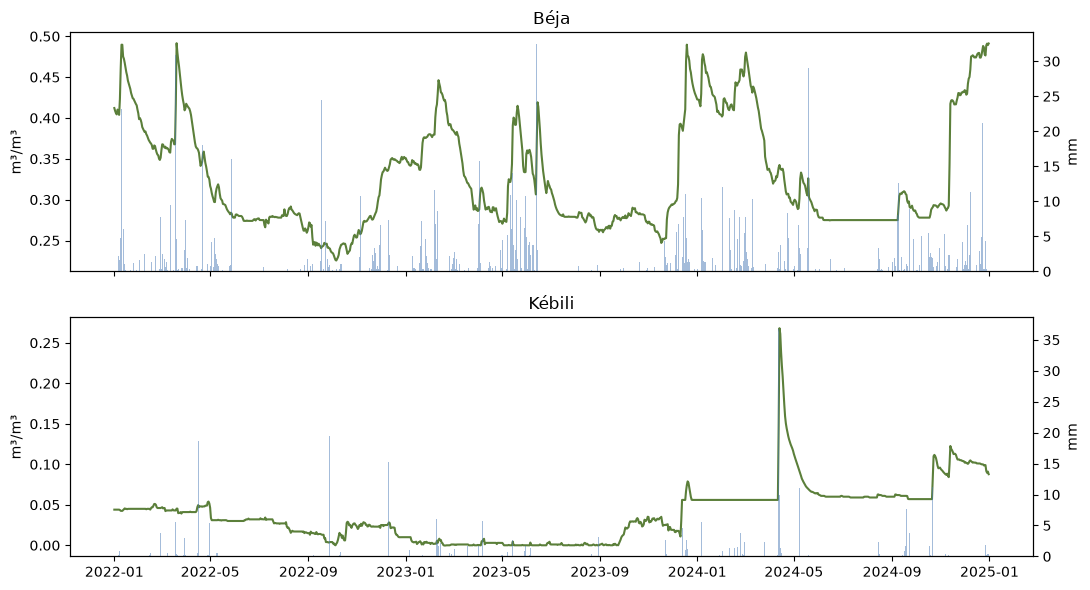

In [4]:
# Aperçu : un site du Nord et une oasis du Sud
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for a, sid in zip(ax, ["beja", "kebili"]):
    d = data[(data.site == sid) & (data.date.dt.year >= 2022)]
    a.plot(d.date, d.sm_7_28, color="#5b7f3a", label="Humidité du sol 7–28 cm")
    a2 = a.twinx(); a2.bar(d.date, d.pluie, color="#4a7bb7", alpha=.5, width=1, label="Pluie (mm)")
    a.set_title(SITES.set_index("id").nom[sid]); a.set_ylabel("m³/m³"); a2.set_ylabel("mm")
fig.tight_layout()

## 3. Construction des variables
Pour chaque jour *J* et chaque site :
- **état actuel du sol** : humidité aux 3 profondeurs, valeurs des jours précédents, variation de la veille ;
- **historique météo** : pluie cumulée sur 1, 3, 7, 30 jours ; ET0 cumulée sur 3, 7, 30 jours ;
- **météo des h prochains jours** (en usage réel : la prévision Open-Meteo) ;
- **lieu et saison** : latitude, longitude, altitude, jour de l'année (sinus / cosinus).

**Cible** pour l'horizon *h* : `humidité(J+h) − humidité(J)`.

In [5]:
def construire_variables(df):
    g = df.sort_values("date").copy()
    s = g[CIBLE]
    for l in [1, 2, 3, 7]:
        g[f"sm_lag{l}"] = s.shift(l)
    g["sm_diff1"] = s - s.shift(1)
    for w in [1, 3, 7, 30]:
        g[f"pluie_{w}j"] = g.pluie.rolling(w).sum()
    for w in [3, 7, 30]:
        g[f"et0_{w}j"] = g.et0.rolling(w).sum()
    doy = g.date.dt.day_of_year
    g["saison_sin"], g["saison_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    for h in HORIZONS:
        futur_pluie = pd.concat([g.pluie.shift(-k) for k in range(1, h + 1)], axis=1)
        futur_et0   = pd.concat([g.et0.shift(-k)   for k in range(1, h + 1)], axis=1)
        g[f"pluie_fut_{h}"]     = futur_pluie.sum(axis=1, min_count=h)
        g[f"pluie_max_fut_{h}"] = futur_pluie.max(axis=1)
        g[f"et0_fut_{h}"]       = futur_et0.sum(axis=1, min_count=h)
        g[f"cible_{h}"]         = s.shift(-h) - s
    return g


BASE = ["sm_0_7", "sm_7_28", "sm_28_100", "sm_lag1", "sm_lag2", "sm_lag3", "sm_lag7", "sm_diff1",
        "pluie", "et0", "tmax", "tmin", "rayonnement", "vent",
        "pluie_1j", "pluie_3j", "pluie_7j", "pluie_30j", "et0_3j", "et0_7j", "et0_30j",
        "lat", "lon", "altitude", "saison_sin", "saison_cos"]
variables = lambda h: BASE + [f"pluie_fut_{h}", f"pluie_max_fut_{h}", f"et0_fut_{h}"]

table = pd.concat([construire_variables(g) for _, g in data.groupby("site")], ignore_index=True)
annee = table.date.dt.year
ENTRAIN   = (~table.test_geo) & (annee <= 2020)
VALID     = (~table.test_geo) & (annee == 2021)
TEST_TEMP = (~table.test_geo) & (annee >= 2022)     # années jamais vues
TEST_GEO  = ( table.test_geo) & (annee >= 2022)     # lieux ET années jamais vus
print({k: int(v.sum()) for k, v in dict(entrainement=ENTRAIN, validation=VALID,
                                        test_annees=TEST_TEMP, test_lieux=TEST_GEO).items()})

{'entrainement': 25578, 'validation': 5110, 'test_annees': 15344, 'test_lieux': 4384}


## 4. Entraînement : un modèle LightGBM par horizon

In [6]:
def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

modeles, resultats = {}, []
for h in HORIZONS:
    X, y = variables(h), f"cible_{h}"
    ok = table[X + [y]].notna().all(axis=1)
    tr, va = table[ENTRAIN & ok], table[VALID & ok]
    m = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.03, num_leaves=63, min_child_samples=40,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
    m.fit(tr[X], tr[y], eval_set=[(va[X], va[y])], callbacks=[lgb.early_stopping(100, verbose=False)])
    modeles[h] = m
    for nom, masque in [("années jamais vues", TEST_TEMP), ("lieux jamais vus", TEST_GEO)]:
        te = table[masque & ok]
        vrai = te[CIBLE] + te[y]                 # humidité réelle à J+h
        pred = te[CIBLE] + m.predict(te[X])      # humidité prédite à J+h
        r_mod, r_per = rmse(vrai, pred), rmse(vrai, te[CIBLE])
        resultats.append(dict(horizon=h, test=nom, rmse_modele=r_mod, rmse_persistance=r_per,
                              gain=1 - r_mod / r_per, arbres=m.best_iteration_))
    print(f"J+{h} entraîné ({m.best_iteration_} arbres)")

res = pd.DataFrame(resultats)
res.pivot(index="horizon", columns="test", values=["rmse_modele", "rmse_persistance", "gain"]).round(4)

J+1 entraîné (201 arbres)


J+2 entraîné (209 arbres)


J+3 entraîné (230 arbres)


J+4 entraîné (244 arbres)


J+5 entraîné (298 arbres)


J+6 entraîné (234 arbres)


J+7 entraîné (199 arbres)


rmse_modele                    rmse_persistance  \
test    années jamais vues lieux jamais vus années jamais vues   
horizon                                                          
1                   0.0042           0.0043             0.0064   
2                   0.0072           0.0075             0.0109   
3                   0.0093           0.0100             0.0144   
4                   0.0109           0.0117             0.0172   
5                   0.0124           0.0129             0.0197   
6                   0.0134           0.0139             0.0218   
7                   0.0144           0.0148             0.0238   

                                       gain                   
test    lieux jamais vus années jamais vues lieux jamais vus  
horizon                                                       
1                 0.0068             0.3389           0.3689  
2                 0.0118             0.3409           0.3627  
3                 0.0155             0.3539           0.3580  
4                 0.0186             0.3676           0.3698  
5                 0.0211             0.3716           0.3890  
6                 0.0233             0.3875           0.4031  
7                 0.0253             0.3941           0.4154

## 5. Résultats
**RMSE** = erreur moyenne en m³/m³ (plus c'est bas, mieux c'est). **Gain** = réduction de l'erreur par rapport à la persistance.

Réduction moyenne de l'erreur par rapport à la persistance :
  années jamais vues   36%
  lieux jamais vus     38%


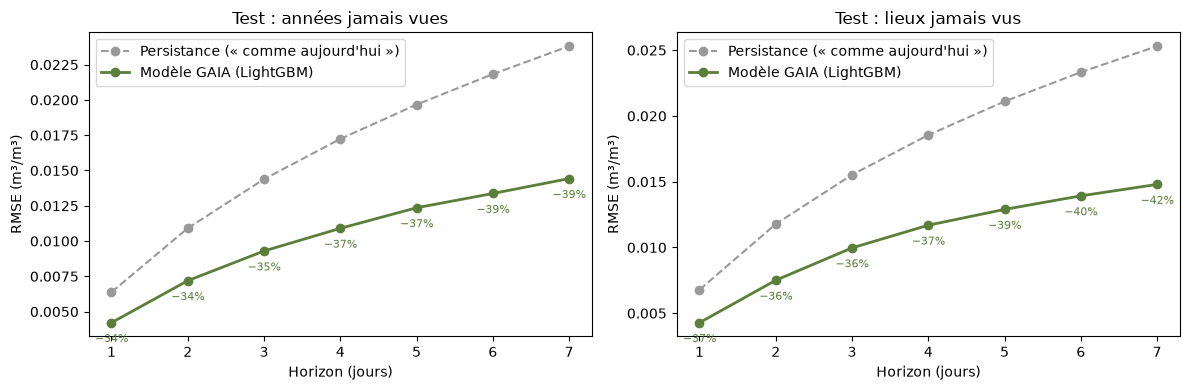

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, nom in zip(ax, ["années jamais vues", "lieux jamais vus"]):
    r = res[res.test == nom]
    a.plot(r.horizon, r.rmse_persistance, "o--", color="#999", label="Persistance (« comme aujourd'hui »)")
    a.plot(r.horizon, r.rmse_modele, "o-", color="#5b7f3a", lw=2, label="Modèle GAIA (LightGBM)")
    for _, row in r.iterrows():
        a.annotate(f"−{row.gain:.0%}", (row.horizon, row.rmse_modele), textcoords="offset points",
                   xytext=(0, -14), ha="center", fontsize=8, color="#5b7f3a")
    a.set_title(f"Test : {nom}"); a.set_xlabel("Horizon (jours)"); a.set_ylabel("RMSE (m³/m³)"); a.legend()
fig.tight_layout()

g = res.groupby("test").gain.mean()
print("Réduction moyenne de l'erreur par rapport à la persistance :")
for k, v in g.items():
    print(f"  {k:20s} {v:.0%}")

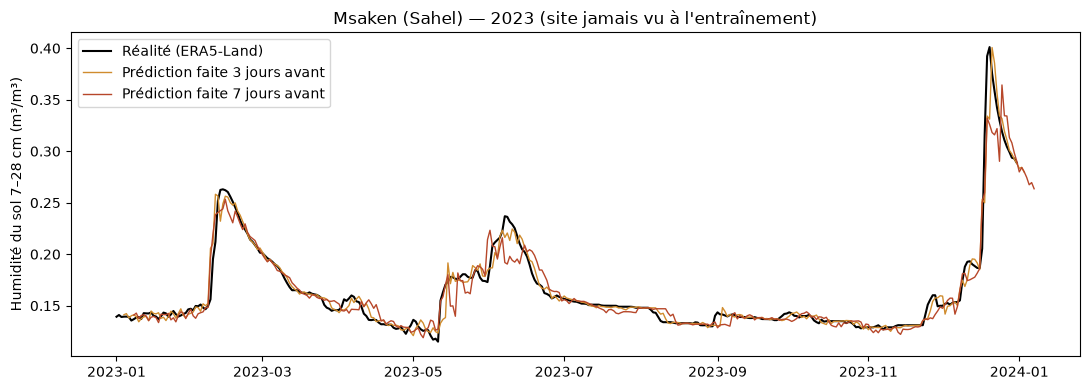

In [8]:
# Exemple sur un site jamais vu : prédiction à J+3 et J+7 comparée à la réalité
SITE_EX = "msaken"
d = table[(table.site == SITE_EX) & (table.date.dt.year == 2023)].copy()
fig, ax = plt.subplots()
ax.plot(d.date, d[CIBLE], color="black", lw=1.5, label="Réalité (ERA5-Land)")
for h, c in [(3, "#d08c2e"), (7, "#b7472a")]:
    X = variables(h); ok = d[X].notna().all(axis=1)
    pred = d.loc[ok, CIBLE] + modeles[h].predict(d.loc[ok, X])
    ax.plot(d.loc[ok, "date"] + pd.Timedelta(days=h), pred, color=c, lw=1, label=f"Prédiction faite {h} jours avant")
ax.set_title(f"{SITES.set_index('id').nom[SITE_EX]} — 2023 (site jamais vu à l'entraînement)")
ax.set_ylabel("Humidité du sol 7–28 cm (m³/m³)"); ax.legend()
fig.tight_layout()

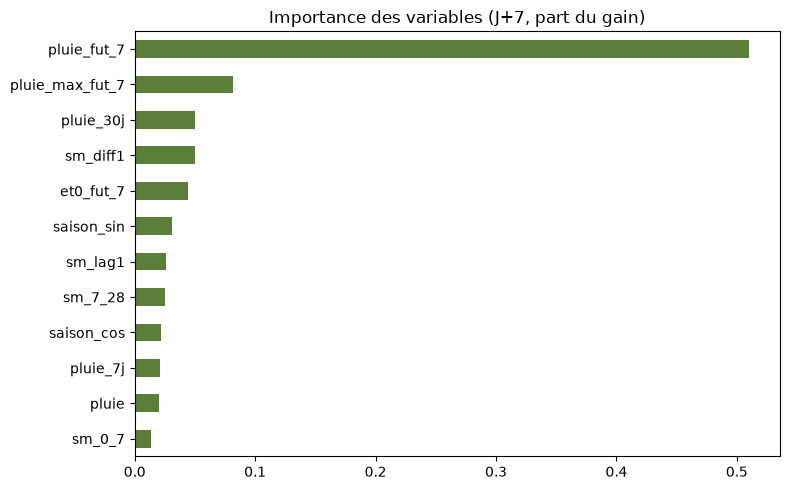

In [9]:
# Ce qui compte le plus pour prédire à J+7
h = 7
imp = pd.Series(modeles[h].booster_.feature_importance("gain"), index=variables(h))
imp = (imp / imp.sum()).sort_values()[-12:]
imp.plot.barh(color="#5b7f3a", figsize=(8, 5), title="Importance des variables (J+7, part du gain)")
plt.tight_layout()

## 6. Sauvegarde des modèles
Les fichiers de `models/` peuvent être chargés par le backend FastAPI (`lightgbm.Booster(model_file=...)`).

In [10]:
for h, m in modeles.items():
    m.booster_.save_model(str(MODEL_DIR / f"humidite_sol_J{h}.txt"))
# seuils sec / humide de chaque site : 5e et 95e centiles de son humidité historique
seuils = data.groupby("site")[CIBLE].quantile([0.05, 0.95]).unstack()
meta = dict(cible=CIBLE, horizons=list(HORIZONS), variables={h: variables(h) for h in HORIZONS},
            source="Open-Meteo Historical API (ERA5 / ERA5-Land)", periode=[START, END],
            resultats=res.round(5).to_dict("records"),
            seuils_sites={s: dict(sec=round(r[0.05], 4), humide=round(r[0.95], 4)) for s, r in seuils.iterrows()})
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")
sorted(p.name for p in MODEL_DIR.iterdir())

['humidite_sol_J1.txt',
 'humidite_sol_J2.txt',
 'humidite_sol_J3.txt',
 'humidite_sol_J4.txt',
 'humidite_sol_J5.txt',
 'humidite_sol_J6.txt',
 'humidite_sol_J7.txt',
 'meta.json']

## 7. De la prédiction à la décision d'irrigation
Pour rester honnête sans inventer de propriétés de sol, la **réserve** est exprimée par rapport à l'historique du site :
0 % = aussi sec que les 5 % des jours les plus secs, 100 % = aussi humide que les 5 % les plus humides.

**Hypothèse de démonstration** (à remplacer par les seuils de la culture, FAO-56) : *irriguer* quand la réserve prévue passe sous **30 %**.

In [11]:
SEUIL_IRRIGATION = 0.30

def reserve(theta, site_id):
    lo, hi = seuils.loc[site_id, 0.05], seuils.loc[site_id, 0.95]
    return float(np.clip((theta - lo) / (hi - lo), 0, 1))


def plan_7_jours(t, site_id):
    # t : table de variables du site ; la dernière ligne = aujourd'hui
    jour = t.iloc[-1]
    lignes = []
    for h in HORIZONS:
        theta = jour[CIBLE] + modeles[h].predict(t.iloc[[-1]][variables(h)])[0]
        r = reserve(theta, site_id)
        d = jour.date + pd.Timedelta(days=h)
        lignes.append(dict(jour=f"{JOURS[d.weekday()]} {d:%d/%m}",
                           pluie_prevue_mm=round(jour[f"pluie_fut_{h}"] - (jour[f"pluie_fut_{h-1}"] if h > 1 else 0), 1),
                           humidite_prevue=round(theta, 3), reserve=f"{r:.0%}",
                           decision="💧 irriguer" if r < SEUIL_IRRIGATION else "—"))
    return pd.DataFrame(lignes)


# Démonstration sur un site jamais vu, en juin 2023, comparée à ce qui s'est réellement passé
site_id, date = "msaken", pd.Timestamp("2023-06-18")
t = table[(table.site == site_id) & (table.date <= date)]
plan = plan_7_jours(t, site_id)
reel = table[(table.site == site_id) & (table.date > date)].head(7)[CIBLE].round(3).values
plan["humidite_reelle"] = reel
plan["reserve_reelle"] = [f"{reserve(v, site_id):.0%}" for v in reel]
print(f"Plan pour {SITES.set_index('id').nom[site_id]} à partir du {date:%d/%m/%Y} "
      f"(réserve aujourd'hui : {reserve(t.iloc[-1][CIBLE], site_id):.0%})")
plan

Plan pour Msaken (Sahel) à partir du 18/06/2023 (réserve aujourd'hui : 39%)


,jour,pluie_prevue_mm,humidite_prevue,reserve,decision,humidite_reelle,reserve_reelle
0,lun 19/06,0.0,0.176,36%,—,0.175,35%
1,mar 20/06,0.0,0.172,33%,—,0.171,33%
2,mer 21/06,0.0,0.170,32%,—,0.170,32%
3,jeu 22/06,0.0,0.167,30%,—,0.168,31%
4,ven 23/06,0.0,0.167,30%,—,0.162,27%
5,sam 24/06,0.0,0.167,30%,—,0.161,27%
6,dim 25/06,0.0,0.166,30%,💧 irriguer,0.160,26%


## 8. Prévision réelle pour la semaine qui vient (nécessite internet)
On prend l'état du sol le plus récent fourni par Open-Meteo (ERA5-Land est publié avec ~5 jours de retard ; les derniers jours peuvent venir d'un modèle de prévision), puis la **prévision météo Open-Meteo** pour les jours suivants. Changez `LAT`, `LON` pour votre parcelle.

In [12]:
LAT, LON = 35.73, 10.58      # Msaken, Sahel — mettez ici les coordonnées de la parcelle

try:
    fin = pd.Timestamp.today().normalize()
    j = appel_open_meteo(URL, dict(latitude=LAT, longitude=LON, start_date=(fin - pd.Timedelta(days=75)).date(),
                                   end_date=fin.date(), daily=",".join(DAILY), hourly=",".join(HOURLY),
                                   timezone="Africa/Tunis"))
    hist = json_vers_table(j)
    hist["altitude"], hist["lat"], hist["lon"] = j["elevation"], LAT, LON
    hist = hist[hist.date <= hist.dropna(subset=[CIBLE, "et0", "pluie"]).date.max()]   # dernier jour complet
    prev = appel_open_meteo("https://api.open-meteo.com/v1/forecast",
                            dict(latitude=LAT, longitude=LON, past_days=14, forecast_days=16, timezone="Africa/Tunis",
                                 daily="et0_fao_evapotranspiration,precipitation_sum"))
    prev = pd.DataFrame(prev["daily"]).rename(columns=RENOMMER)
    prev["date"] = pd.to_datetime(prev.pop("time"))
    futur = prev[prev.date > hist.date.max()].head(7)
    t = construire_variables(pd.concat([hist, futur], ignore_index=True))
    t = t[t.date <= hist.date.max()]
    site_proche = SITES.assign(d=(SITES.lat - LAT) ** 2 + (SITES.lon - LON) ** 2).sort_values("d").id.iloc[0]
    print(f"État du sol le plus récent fourni par Open-Meteo : {hist.date.max():%d/%m/%Y} "
          "(les tout derniers jours peuvent venir d'un modèle de prévision plutôt que d'ERA5-Land).")
    print("Météo des jours suivants = prévision Open-Meteo.")
    print(f"Seuils sec/humide empruntés au site d'entraînement le plus proche : {site_proche}")
    display(plan_7_jours(t, site_proche))
except Exception as e:
    print("Prévision en direct indisponible :", e)

État du sol le plus récent fourni par Open-Meteo : 21/11/2026 (les tout derniers jours peuvent venir d'un modèle de prévision plutôt que d'ERA5-Land).
Météo des jours suivants = prévision Open-Meteo.
Seuils sec/humide empruntés au site d'entraînement le plus proche : msaken


,jour,pluie_prevue_mm,humidite_prevue,reserve,decision
0,dim 22/11,0.0,0.217,60%,—
1,lun 23/11,0.0,0.215,58%,—
2,mar 24/11,0.0,0.213,57%,—
3,mer 25/11,0.0,0.213,57%,—
4,jeu 26/11,0.6,0.211,56%,—
5,ven 27/11,3.0,0.213,57%,—
6,sam 28/11,0.0,0.214,57%,—


## Ce qu'il faut retenir
- Le modèle a **appris à partir de 9 ans de données sur 18 sites tunisiens** et il est testé sur des **années** et des **lieux** qu'il n'a jamais vus.
- Il fait mieux que la persistance à tous les horizons (voir le graphique de la section 5) ; l'erreur augmente avec l'horizon, ce que GAIA affiche comme **confiance**.
- **Pistes d'amélioration :** ajouter les propriétés du sol SoilGrids ; vérifier avec l'humidité satellite **NASA SMAP** ; affiner sur une parcelle avec le **capteur de sol** (Kaizen) ; remplacer le seuil de 30 % par les seuils FAO-56 de la culture.